# 01 · The Explosion

**The traveling salesman problem is everywhere, and your exact solver gives up at 20 stops.**

This is the showpiece. Before any solver, feel *why* routing is hard: the number of possible
tours through `n` stops grows **factorially**. We put that growth next to a physical yardstick —
the number of atoms in the observable universe — and then watch brute-force enumeration slow
from instant to hopeless across a handful of added stops.

Every figure is saved to `outputs/figures/` and every number to `outputs/data/`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from src.evaluation.scaling import ATOMS_IN_OBSERVABLE_UNIVERSE, tour_count, time_call
from src.exact.brute_force import brute_force_tsp
from src.problems.tsp import generate_tsp_instance
from src.reporting import save_figure, save_json
from src.visualisation import plot_explosion

SEED = 42
print(f"atoms in the observable universe ~ {ATOMS_IN_OBSERVABLE_UNIVERSE:.0e}")

atoms in the observable universe ~ 1e+80


## 1. Counting the tours

There are `(n-1)!/2` distinct undirected tours through `n` stops. Ten stops is trivial; fifty
stops already has more tours than the universe has atoms.

In [2]:
ladder = [5, 10, 15, 20, 25, 30, 40, 50]
counts = {n: tour_count(n) for n in ladder}

rows = []
for n in ladder:
    c = counts[n]
    rows.append({
        "stops": n,
        "distinct_tours": c,
        "tours_scientific": f"{c:.3e}",
        "times_atoms_in_universe": c / ATOMS_IN_OBSERVABLE_UNIVERSE,
    })

for r in rows:
    print(f"{r['stops']:>3} stops -> {r['tours_scientific']:>12} tours"
          f"  ({r['times_atoms_in_universe']:.2e} x atoms in universe)")

save_json("01_tour_counts", {
    "formula": "(n-1)!/2 distinct undirected tours",
    "atoms_in_observable_universe": ATOMS_IN_OBSERVABLE_UNIVERSE,
    "rows": rows,
})

  5 stops ->    1.200e+01 tours  (1.20e-79 x atoms in universe)
 10 stops ->    1.814e+05 tours  (1.81e-75 x atoms in universe)
 15 stops ->    4.359e+10 tours  (4.36e-70 x atoms in universe)
 20 stops ->    6.082e+16 tours  (6.08e-64 x atoms in universe)
 25 stops ->    3.102e+23 tours  (3.10e-57 x atoms in universe)
 30 stops ->    4.421e+30 tours  (4.42e-50 x atoms in universe)
 40 stops ->    1.020e+46 tours  (1.02e-34 x atoms in universe)
 50 stops ->    3.041e+62 tours  (3.04e-18 x atoms in universe)


PosixPath('/workspaces/routing_arena/outputs/data/01_tour_counts.json')

## 2. The explosion, plotted

Tour count against stops on a log scale, with the atoms-in-the-universe line for scale.

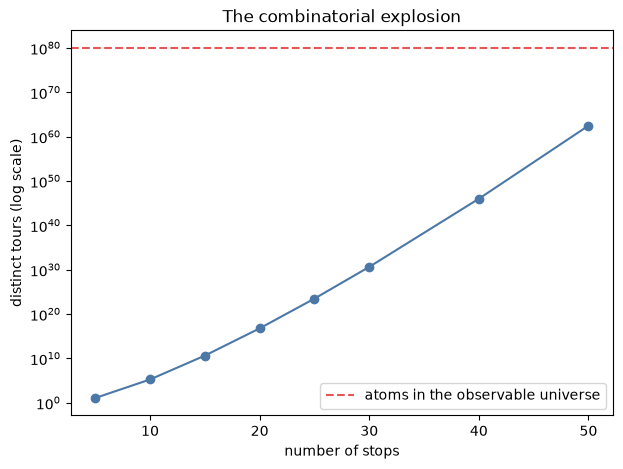

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_explosion(ladder, [counts[n] for n in ladder], ax=ax)
save_figure(fig, "01_explosion_curve")
plt.show()

## 3. Watch brute force die

Brute force enumerates every tour, so its runtime tracks that factorial curve. We fix stop 0 as
the start (that removes a trivial factor) and time it as stops are added. It is instant at ten
stops and already painful at eleven; twelve would take roughly ten times longer again.

In [4]:
bf_sizes = list(range(4, 12))
bf_rows = []
for n in bf_sizes:
    instance = generate_tsp_instance(n, seed=SEED)
    (_, length), seconds = time_call(lambda inst=instance: brute_force_tsp(inst.distances, max_n=12))
    bf_rows.append({"stops": n, "seconds": seconds, "optimal_length": length,
                    "distinct_tours": tour_count(n)})
    print(f"{n:>3} stops -> {seconds:8.3f} s   (optimal length {length:7.2f})")

save_json("01_brute_force_scaling", {"seed": SEED, "rows": bf_rows})

  4 stops ->    0.000 s   (optimal length  196.33)
  5 stops ->    0.000 s   (optimal length  226.94)
  6 stops ->    0.000 s   (optimal length  227.19)
  7 stops ->    0.001 s   (optimal length  227.20)
  8 stops ->    0.008 s   (optimal length  240.49)
  9 stops ->    0.078 s   (optimal length  264.45)


 10 stops ->    0.766 s   (optimal length  264.53)


 11 stops ->    8.033 s   (optimal length  265.15)


PosixPath('/workspaces/routing_arena/outputs/data/01_brute_force_scaling.json')

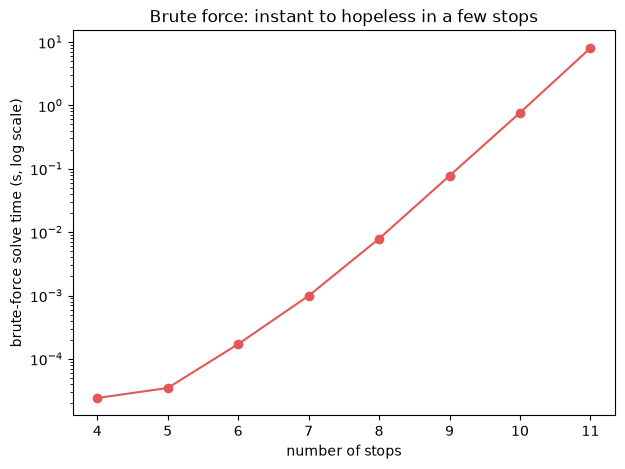

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy([r["stops"] for r in bf_rows], [r["seconds"] for r in bf_rows], "-o", color="#E45756")
ax.set_xlabel("number of stops")
ax.set_ylabel("brute-force solve time (s, log scale)")
ax.set_title("Brute force: instant to hopeless in a few stops")
save_figure(fig, "01_brute_force_time")
plt.show()

## Takeaway

The tour count outruns every computer there will ever be. "Just solve it exactly" stops being a
plan before you reach the size of a single delivery van's route. The rest of this project is about
what to do instead — and how close *instead* can get.

Next: **02 · Exact TSP** — how far a real exact solver actually reaches before the same wall
arrives.